<a href="https://colab.research.google.com/github/vu21eece0100463/traffic-light-detection/blob/main/Traffic_Light_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q opencv-python pillow

In [2]:
!pip install -q ultralytics opencv-python-headless

<IPython.core.display.Javascript object>

Starting webcam...
Monitoring started.
Click Stop Monitoring when finished.
{
  "timestamp": "2026-11-03T11:30:07.603125",
  "traffic_head_id": 1,
  "red": "OFF",
  "amber": "OFF",
  "green": "OFF",
  "active_status": "UNKNOWN",
  "duration_seconds": 0,
  "duration_minutes": 0.0,
  "red_color_score": 0.0,
  "amber_color_score": 0.0,
  "green_color_score": 0.0
}


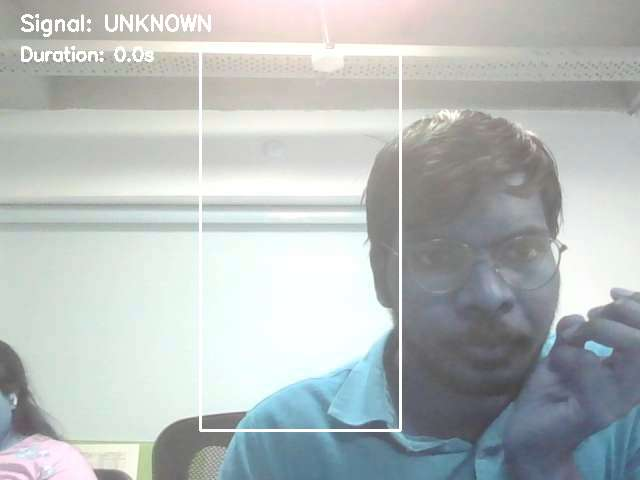

{
  "timestamp": "2026-11-03T11:30:12.745794",
  "traffic_head_id": 1,
  "red": "OFF",
  "amber": "OFF",
  "green": "OFF",
  "active_status": "UNKNOWN",
  "duration_seconds": 0,
  "duration_minutes": 0.0,
  "red_color_score": 0.0,
  "amber_color_score": 0.0,
  "green_color_score": 0.0
}
{
  "timestamp": "2026-11-03T11:30:18.086316",
  "traffic_head_id": 1,
  "red": "OFF",
  "amber": "OFF",
  "green": "OFF",
  "active_status": "UNKNOWN",
  "duration_seconds": 0,
  "duration_minutes": 0.0,
  "red_color_score": 0.0,
  "amber_color_score": 0.0,
  "green_color_score": 0.0
}
{
  "timestamp": "2026-11-03T11:30:23.298926",
  "traffic_head_id": 1,
  "red": "OFF",
  "amber": "OFF",
  "green": "OFF",
  "active_status": "UNKNOWN",
  "duration_seconds": 0,
  "duration_minutes": 0.0,
  "red_color_score": 0.0,
  "amber_color_score": 0.0,
  "green_color_score": 0.0
}
{
  "timestamp": "2026-11-03T11:30:28.735547",
  "traffic_head_id": 1,
  "red": "OFF",
  "amber": "OFF",
  "green": "OFF",
  "active_sta

In [1]:
# ============================================================
# FAST TRAFFIC LIGHT DETECTION + RENDER API UPLOAD
# Google Colab optimized version
# ============================================================

import cv2
import numpy as np
import json
import time
import requests

from datetime import datetime
from base64 import b64decode
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js


# ============================================================
# 1. API CONFIGURATION
# ============================================================

API_URL = "https://traffic-light-api-a50q.onrender.com"

# Use your newly generated secret (do not reuse exposed secret)
API_SECRET = "PASTE_YOUR_NEW_API_SECRET_HERE"

UPLOAD_TO_API = True

headers = {
    "x-api-key": API_SECRET,
    "Content-Type": "application/json"
}


# ============================================================
# 2. PERFORMANCE SETTINGS
# ============================================================

# Process only every 0.25 seconds = around 4 FPS
PROCESS_INTERVAL = 0.25

# Display processed frame every 3 frames
DISPLAY_EVERY_N_FRAMES = 3

# Save a record when state changes or every 5 seconds
RECORD_INTERVAL = 5.0

# Batch size for API uploads
BATCH_SIZE = 50


# ============================================================
# 3. TRAFFIC LIGHT CONFIGURATION
# ============================================================

# Adjust this ROI according to your traffic signal position
ROI = (200, 50, 400, 430)

TRAFFIC_HEAD_ID = 1

COLOR_THRESHOLD = 5


# ============================================================
# 4. RECORD STORAGE
# ============================================================

records = []

active_status = "UNKNOWN"
state_start_time = None

last_record_time = 0
previous_recorded_status = None

frame_count = 0


# ============================================================
# 5. HSV COLOR DETECTION
# ============================================================

def detect_lamp(roi, lamp):

    if roi is None or roi.size == 0:
        return False, 0.0

    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)

    if lamp == "RED":

        mask1 = cv2.inRange(
            hsv,
            np.array([0, 120, 160]),
            np.array([10, 255, 255])
        )

        mask2 = cv2.inRange(
            hsv,
            np.array([170, 120, 160]),
            np.array([180, 255, 255])
        )

        mask = mask1 | mask2

    elif lamp == "AMBER":

        mask = cv2.inRange(
            hsv,
            np.array([11, 100, 160]),
            np.array([35, 255, 255])
        )

    elif lamp == "GREEN":

        mask = cv2.inRange(
            hsv,
            np.array([36, 70, 120]),
            np.array([90, 255, 255])
        )

    else:
        return False, 0.0

    total_pixels = roi.shape[0] * roi.shape[1]

    if total_pixels == 0:
        return False, 0.0

    active_pixels = cv2.countNonZero(mask)

    score = (active_pixels / total_pixels) * 100

    return score > COLOR_THRESHOLD, round(score, 2)


# ============================================================
# 6. COLAB WEBCAM JAVASCRIPT
# ============================================================

display(Javascript("""
async function initFastCamera() {

    const container = document.createElement('div');
    container.id = 'fast-traffic-camera';

    const video = document.createElement('video');

    video.width = 640;
    video.height = 480;
    video.autoplay = true;
    video.playsInline = true;
    video.style.display = 'block';

    const stopButton = document.createElement('button');
    stopButton.textContent = 'Stop Monitoring';

    const stream = await navigator.mediaDevices.getUserMedia({
        video: {
            width: 640,
            height: 480
        },
        audio: false
    });

    video.srcObject = stream;
    await video.play();

    const canvas = document.createElement('canvas');
    canvas.width = 640;
    canvas.height = 480;

    container.appendChild(video);
    container.appendChild(stopButton);

    document.body.appendChild(container);

    window.fastTrafficVideo = video;
    window.fastTrafficStream = stream;
    window.fastTrafficCanvas = canvas;
    window.fastTrafficStopped = false;

    stopButton.onclick = () => {
        stream.getTracks().forEach(track => track.stop());
        window.fastTrafficStopped = true;
        container.remove();
    };
}

async function captureFastFrame() {

    if (window.fastTrafficStopped ||
        !window.fastTrafficVideo ||
        !window.fastTrafficStream) {
        return null;
    }

    const video = window.fastTrafficVideo;
    const canvas = window.fastTrafficCanvas;

    if (video.readyState < 2) {
        return null;
    }

    const ctx = canvas.getContext('2d');

    ctx.drawImage(video, 0, 0, 640, 480);

    return canvas.toDataURL('image/jpeg', 0.6);
}

function stopFastCamera() {

    if (window.fastTrafficStream) {
        window.fastTrafficStream.getTracks().forEach(track => track.stop());
    }

    window.fastTrafficStopped = true;

    const container = document.getElementById('fast-traffic-camera');

    if (container) {
        container.remove();
    }
}
"""))


# ============================================================
# 7. START WEBCAM
# ============================================================

print("Starting webcam...")

eval_js("initFastCamera()")

print("Monitoring started.")
print("Click Stop Monitoring when finished.")


# ============================================================
# 8. FAST DETECTION LOOP
# ============================================================

display_handle = None

try:

    while True:

        loop_start = time.monotonic()

        frame_data = eval_js("captureFastFrame()")

        if not frame_data:
            print("Camera stopped.")
            break

        # Decode image
        image_bytes = b64decode(frame_data.split(",")[1])

        frame = cv2.imdecode(
            np.frombuffer(image_bytes, dtype=np.uint8),
            cv2.IMREAD_COLOR
        )

        if frame is None:
            continue

        frame_count += 1

        height, width = frame.shape[:2]

        # Clamp ROI to image dimensions
        x1, y1, x2, y2 = ROI

        x1 = max(0, min(x1, width))
        x2 = max(0, min(x2, width))

        y1 = max(0, min(y1, height))
        y2 = max(0, min(y2, height))

        traffic_roi = frame[y1:y2, x1:x2]

        if traffic_roi.size == 0:
            continue

        roi_height = traffic_roi.shape[0]

        section = roi_height // 3

        if section <= 0:
            continue

        red_roi = traffic_roi[:section, :]

        amber_roi = traffic_roi[
            section:section * 2, :
        ]

        green_roi = traffic_roi[
            section * 2:roi_height, :
        ]


        # ----------------------------------------------------
        # Detect colors
        # ----------------------------------------------------

        red_on, red_score = detect_lamp(red_roi, "RED")

        amber_on, amber_score = detect_lamp(
            amber_roi, "AMBER"
        )

        green_on, green_score = detect_lamp(
            green_roi, "GREEN"
        )


        # ----------------------------------------------------
        # Determine active signal
        # ----------------------------------------------------

        if red_on and not amber_on and not green_on:
            current_status = "RED"

        elif amber_on and not red_on and not green_on:
            current_status = "AMBER"

        elif green_on and not red_on and not amber_on:
            current_status = "GREEN"

        else:
            current_status = "UNKNOWN"


        # ----------------------------------------------------
        # Track signal duration
        # ----------------------------------------------------

        now = time.monotonic()

        state_changed = current_status != active_status

        if state_changed:

            active_status = current_status

            state_start_time = now

            print("Signal changed:", active_status)

        if state_start_time is not None:

            duration = now - state_start_time

        else:

            duration = 0


        # ----------------------------------------------------
        # Save record only when needed
        # ----------------------------------------------------

        should_record = (
            state_changed or
            now - last_record_time >= RECORD_INTERVAL
        )

        if should_record:

            record = {

                "timestamp": datetime.now().isoformat(),

                "traffic_head_id": TRAFFIC_HEAD_ID,

                "red": "ON" if red_on else "OFF",

                "amber": "ON" if amber_on else "OFF",

                "green": "ON" if green_on else "OFF",

                "active_status": active_status,

                "duration_seconds": round(duration, 2),

                "duration_minutes": round(duration / 60, 2),

                "red_color_score": red_score,

                "amber_color_score": amber_score,

                "green_color_score": green_score

            }

            records.append(record)

            last_record_time = now

            previous_recorded_status = active_status

            print(json.dumps(record, indent=2))


        # ----------------------------------------------------
        # Draw simple overlay
        # ----------------------------------------------------

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (255, 255, 255),
            2
        )

        cv2.putText(
            frame,
            f"Signal: {active_status}",
            (20, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 255, 255),
            2
        )

        cv2.putText(
            frame,
            f"Duration: {duration:.1f}s",
            (20, 60),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 255, 255),
            2
        )


        # ----------------------------------------------------
        # Update display only occasionally
        # ----------------------------------------------------

        if frame_count % DISPLAY_EVERY_N_FRAMES == 0:

            frame_rgb = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            success, encoded = cv2.imencode(
                ".jpg",
                frame_rgb,
                [cv2.IMWRITE_JPEG_QUALITY, 60]
            )

            if success:

                img = Image(data=encoded.tobytes())

                if display_handle is None:

                    display_handle = display(
                        img,
                        display_id=True
                    )

                else:

                    display_handle.update(img)


        # ----------------------------------------------------
        # Limit processing frequency
        # ----------------------------------------------------

        elapsed = time.monotonic() - loop_start

        sleep_time = PROCESS_INTERVAL - elapsed

        if sleep_time > 0:
            time.sleep(sleep_time)


except KeyboardInterrupt:

    print("Monitoring stopped by user.")

except Exception as error:

    print("Detection error:", str(error))

finally:

    try:
        eval_js("stopFastCamera()")
    except Exception:
        pass


# ============================================================
# 9. DETECTION SUMMARY
# ============================================================

print("\n========== DETECTION SUMMARY ==========")

print("Frames processed:", frame_count)

print("Records collected:", len(records))

print("======================================")


# ============================================================
# 10. UPLOAD TO RENDER API
# ============================================================

if not UPLOAD_TO_API:

    print("API upload disabled.")

elif not records:

    print("No records available.")

elif API_SECRET == "PASTE_YOUR_NEW_API_SECRET_HERE":

    print("Please configure your API_SECRET.")

else:

    print("\nUploading records to Render...")

    batch_url = API_URL.rstrip("/") + "/api/traffic/batch"

    single_url = API_URL.rstrip("/") + "/api/traffic"

    successful = 0
    failed = 0

    # --------------------------------------------------------
    # Try batch endpoint first
    # --------------------------------------------------------

    try:

        batch_response = requests.post(
            batch_url,
            headers=headers,
            json={"records": records},
            timeout=60
        )

        if batch_response.status_code in (200, 201):

            successful = len(records)

            print("Batch upload successful.")

        elif batch_response.status_code in (404, 405):

            print("Batch endpoint not available.")
            print("Uploading records individually...")

            for record in records:

                try:

                    response = requests.post(
                        single_url,
                        headers=headers,
                        json=record,
                        timeout=30
                    )

                    if response.status_code in (200, 201):

                        successful += 1

                    else:

                        failed += 1

                        print(
                            "Failed:",
                            response.status_code,
                            response.text
                        )

                except requests.exceptions.RequestException as error:

                    failed += 1

                    print("Request error:", error)

        else:

            failed = len(records)

            print("Batch upload failed:")
            print(batch_response.status_code)
            print(batch_response.text)

    except requests.exceptions.RequestException as error:

        failed = len(records)

        print("API connection error:", error)


    # --------------------------------------------------------
    # Final upload report
    # --------------------------------------------------------

    print("\n========== UPLOAD SUMMARY ==========")

    print("Total records:", len(records))

    print("Successful:", successful)

    print("Failed:", failed)

    print("====================================")

<IPython.core.display.Javascript object>

Saved to photo.jpg


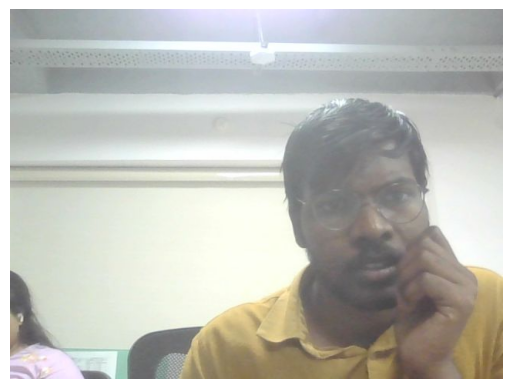

In [2]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  import matplotlib.pyplot as plt
  img = cv2.imread(filename)
  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.axis('off')
  plt.show()
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

In [3]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np
import json
import time
from datetime import datetime

# ==========================================================
# 1. JAVASCRIPT WEBCAM STREAM
# ==========================================================

def video_stream_script():
    js = Javascript("""
    var video;
    var div;
    var stream;
    var canvas;

    async function initCamera() {
        div = document.createElement('div');
        div.id = "webcam-container";

        video = document.createElement('video');
        video.style.display = 'block';
        video.width = 640;
        video.height = 480;
        video.autoplay = true;

        stream = await navigator.mediaDevices.getUserMedia({
            video: {
                width: 640,
                height: 480
            }
        });

        video.srcObject = stream;
        await video.play();

        canvas = document.createElement('canvas');
        canvas.width = 640;
        canvas.height = 480;

        document.body.appendChild(div);
        div.appendChild(video);

        const stopBtn = document.createElement('button');
        stopBtn.textContent = 'Stop Stream';

        stopBtn.onclick = () => {
            stream.getTracks().forEach(track => track.stop());
            div.remove();
        };

        div.appendChild(stopBtn);
    }

    async function captureFrame() {
        if (!stream ||
            stream.getVideoTracks().length === 0 ||
            stream.getVideoTracks()[0].readyState === 'ended') {
            return null;
        }

        const ctx = canvas.getContext('2d');

        ctx.drawImage(video, 0, 0, 640, 480);

        return canvas.toDataURL('image/jpeg', 0.8);
    }
    """)

    display(js)


# ==========================================================
# 2. TRAFFIC LIGHT COLOR DETECTION
# ==========================================================

def detect_lamp(roi, lamp):

    if roi.size == 0:
        return False

    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)

    if lamp == "RED":

        mask1 = cv2.inRange(
            hsv,
            np.array([0, 120, 160]),
            np.array([10, 255, 255])
        )

        mask2 = cv2.inRange(
            hsv,
            np.array([170, 120, 160]),
            np.array([180, 255, 255])
        )

        mask = mask1 | mask2

    elif lamp == "AMBER":

        mask = cv2.inRange(
            hsv,
            np.array([11, 100, 160]),
            np.array([35, 255, 255])
        )

    elif lamp == "GREEN":

        mask = cv2.inRange(
            hsv,
            np.array([36, 70, 120]),
            np.array([90, 255, 255])
        )

    active_pixels = cv2.countNonZero(mask)

    total_pixels = roi.shape[0] * roi.shape[1]

    if total_pixels == 0:
        return False

    percentage = (active_pixels / total_pixels) * 100

    return percentage > 5


# ==========================================================
# 3. CONFIGURATION
# ==========================================================

# Adjust according to the traffic signal position.
# Camera dimensions: 640 x 480

ROI = (200, 50, 400, 430)

traffic_head_id = 1

# How frequently to print JSON while state remains unchanged
JSON_INTERVAL = 1.0  # seconds


# ==========================================================
# 4. TRAFFIC LIGHT DURATION VARIABLES
# ==========================================================

previous_status = None

active_status = "UNKNOWN"

state_start_time = None

last_json_time = 0

# Use monotonic clock for elapsed duration
start_clock = time.monotonic()


# ==========================================================
# 5. START CAMERA
# ==========================================================

video_stream_script()

eval_js('initCamera()')

print("Traffic light monitoring started.")
print("Click Stop Stream to stop camera.")


# ==========================================================
# 6. CONTINUOUS TRAFFIC LIGHT MONITORING
# ==========================================================

try:

    while True:

        frame_data = eval_js('captureFrame()')

        if not frame_data:
            print("Camera stopped.")
            break

        # Decode webcam frame
        binary = b64decode(frame_data.split(',')[1])

        img_array = np.frombuffer(
            binary,
            dtype=np.uint8
        )

        frame = cv2.imdecode(
            img_array,
            cv2.IMREAD_COLOR
        )

        if frame is None:
            continue

        # Extract traffic light region
        x1, y1, x2, y2 = ROI

        traffic_head = frame[y1:y2, x1:x2]

        if traffic_head.size == 0:
            continue

        height = traffic_head.shape[0]

        section = height // 3

        # Divide into 3 lamp regions
        red_roi = traffic_head[0:section, :]

        amber_roi = traffic_head[
            section:section * 2, :
        ]

        green_roi = traffic_head[
            section * 2:height, :
        ]

        # Detect lamp colors
        red_on = detect_lamp(red_roi, "RED")

        amber_on = detect_lamp(amber_roi, "AMBER")

        green_on = detect_lamp(green_roi, "GREEN")


        # ==================================================
        # 7. DETERMINE ACTIVE TRAFFIC LIGHT
        # ==================================================

        if red_on and not amber_on and not green_on:

            current_status = "RED"

        elif amber_on and not red_on and not green_on:

            current_status = "AMBER"

        elif green_on and not red_on and not amber_on:

            current_status = "GREEN"

        else:

            # No lamp or conflicting detections
            current_status = "UNKNOWN"


        # ==================================================
        # 8. CALCULATE STATE DURATION
        # ==================================================

        current_time = time.monotonic()

        # New state detected
        if current_status != active_status:

            active_status = current_status

            state_start_time = current_time

            print(
                f"Traffic light changed to: {active_status}"
            )

        # Calculate elapsed time for current state
        if state_start_time is not None:

            duration_seconds = (
                current_time - state_start_time
            )

        else:

            duration_seconds = 0


        # ==================================================
        # 9. CREATE STATUS JSON
        # ==================================================

        status = {

            "traffic_head_id": traffic_head_id,

            "red": "ON" if red_on else "OFF",

            "amber": "ON" if amber_on else "OFF",

            "green": "ON" if green_on else "OFF",

            "active_status": active_status,

            "duration_seconds": round(
                duration_seconds, 2
            ),

            "duration_minutes": round(
                duration_seconds / 60, 2
            )

        }


        # ==================================================
        # 10. PRINT JSON EVERY SECOND OR ON STATE CHANGE
        # ==================================================

        state_changed = (
            status["active_status"] !=
            (
                previous_status["active_status"]
                if previous_status else None
            )
        )

        if (
            state_changed or
            current_time - last_json_time >= JSON_INTERVAL
        ):

            output = {

                "timestamp": datetime.now().isoformat(),

                **status

            }

            print(
                json.dumps(
                    output,
                    indent=4
                )
            )

            previous_status = status.copy()

            last_json_time = current_time


except KeyboardInterrupt:

    print("Monitoring interrupted.")

except Exception as e:

    print("Monitoring stopped:", str(e))


<IPython.core.display.Javascript object>

Traffic light monitoring started.
Click Stop Stream to stop camera.
{
    "timestamp": "2026-11-03T11:30:46.764803",
    "traffic_head_id": 1,
    "red": "OFF",
    "amber": "OFF",
    "green": "OFF",
    "active_status": "UNKNOWN",
    "duration_seconds": 0,
    "duration_minutes": 0.0
}
{
    "timestamp": "2026-11-03T11:30:48.342011",
    "traffic_head_id": 1,
    "red": "OFF",
    "amber": "OFF",
    "green": "OFF",
    "active_status": "UNKNOWN",
    "duration_seconds": 0,
    "duration_minutes": 0.0
}
{
    "timestamp": "2026-11-03T11:30:49.691083",
    "traffic_head_id": 1,
    "red": "OFF",
    "amber": "OFF",
    "green": "OFF",
    "active_status": "UNKNOWN",
    "duration_seconds": 0,
    "duration_minutes": 0.0
}
{
    "timestamp": "2026-11-03T11:30:51.064034",
    "traffic_head_id": 1,
    "red": "OFF",
    "amber": "OFF",
    "green": "OFF",
    "active_status": "UNKNOWN",
    "duration_seconds": 0,
    "duration_minutes": 0.0
}
{
    "timestamp": "2026-11-03T11:30:52.1076

In [4]:
import requests
import json

# --------------------------------------------------
# API CONFIGURATION
# --------------------------------------------------

API_URL = "https://traffic-light-api-a50q.onrender.com/api/traffic"

# Replace this with your NEW API_SECRET
API_SECRET = "PASTE_YOUR_NEW_API_SECRET_HERE"

headers = {
    "x-api-key": API_SECRET,
    "Content-Type": "application/json"
}

# --------------------------------------------------
# CHECK YOLO DETECTION RECORDS
# --------------------------------------------------

records = globals().get("records", None)

if records is None:
    print("ERROR: YOLO detection records are not available.")
    print("Please run your YOLO video-processing cell first.")

elif not records:
    print("ERROR: The records list is empty. No data to upload.")

else:
    print(f"Found {len(records)} detection records.")

    successful = 0
    failed = 0

    # --------------------------------------------------
    # UPLOAD RECORDS TO NODE.JS API
    # --------------------------------------------------

    for index, record in enumerate(records, start=1):

        try:
            response = requests.post(
                API_URL,
                headers=headers,
                json=record,
                timeout=30
            )

            if response.status_code == 201:
                successful += 1
                print(f"Record {index} uploaded successfully.")

            else:
                failed += 1
                print(f"Record {index} upload failed.")
                print("Status:", response.status_code)
                print("Response:", response.text)

        except requests.exceptions.RequestException as error:
            failed += 1
            print(f"Record {index} connection error:", error)

    # --------------------------------------------------
    # SUMMARY
    # --------------------------------------------------

    print("\n========== UPLOAD SUMMARY ==========")
    print("Total records:", len(records))
    print("Successful uploads:", successful)
    print("Failed uploads:", failed)
    print("===================================")

Found 5 detection records.
Record 1 upload failed.
Status: 401
Response: {"success":false,"message":"Unauthorized: Invalid API key"}
Record 2 upload failed.
Status: 401
Response: {"success":false,"message":"Unauthorized: Invalid API key"}
Record 3 upload failed.
Status: 401
Response: {"success":false,"message":"Unauthorized: Invalid API key"}
Record 4 upload failed.
Status: 401
Response: {"success":false,"message":"Unauthorized: Invalid API key"}
Record 5 upload failed.
Status: 401
Response: {"success":false,"message":"Unauthorized: Invalid API key"}

========== UPLOAD SUMMARY ==========
Total records: 5
Successful uploads: 0
Failed uploads: 5


In [6]:
import requests
import json

# Your actual Render API URL
API_URL = "https://traffic-light-api-a50q.onrender.com/api/traffic?limit=20"

# Use your NEW API secret
API_SECRET = "PASTE_YOUR_NEW_API_SECRET_HERE"

headers = {
    "x-api-key": API_SECRET,
    "Content-Type": "application/json"
}

try:
    print("Connecting to Render API...")

    response = requests.get(
        API_URL,
        headers=headers,
        timeout=60
    )

    print("HTTP Status:", response.status_code)

    if response.status_code == 200:

        data = response.json()

        print("\nTraffic records retrieved successfully:\n")

        print(json.dumps(data, indent=4))

    elif response.status_code == 401:

        print("Authentication failed.")
        print("Check API_SECRET in Colab and Render.")

    elif response.status_code == 404:

        print("API route not found.")
        print("Check whether GET /api/traffic exists in server.js.")

    else:

        print("API request failed:")
        print(response.text)

except requests.exceptions.RequestException as error:

    print("Connection error:", str(error))

Connecting to Render API...
HTTP Status: 401
Authentication failed.
Check API_SECRET in Colab and Render.
